# Neural ODE: learning one dynamical law from multiple datasets

In this notebook, we learn a dynamical system from **multiple time-series datasets**, each starting from a different initial condition.

We generate synthetic data using the first-order decay model

$$\frac{dx}{dt}=-kx, \qquad x(t)=x_0e^{-kt}.$$

Imagine that the differential equation is unknown and only the observed trajectories are available. We represent the unknown rate law using a neural network:

$$\frac{dx}{dt}=N_{\theta}(x).$$

**Key idea:** Every dataset has a different initial value $x_0^{(j)}$, but the same underlying rate law. We therefore train **one neural network with one shared set of parameters** $\theta$ using all the trajectories.

We write the neural network directly in Julia rather than using `Lux.jl` or `DiffEqFlux.jl`, so that the main steps of neural ODE training remain visible. At the end, we test the learned model with a new initial condition.

#### Install packages

This notebook uses the following Julia packages:


`Plots`: For plotting data.


`Random`: For random number generation.


`ForwardDiff`: For calculating the gradient of the loss function.

`Optimizers`: To update parameters using Adam, a gradient-based optimization algorithm.

`DifferentialEquations.jl`: To solve neural ODEs, just like a standard ODE.

Install these packages before using this notebook:

`you@you:~$ julia`


`julia> using Pkg`


`julia> Pkg.add("ForwardDiff")`

In [1]:
# 1. Load the Packages

using Plots, Random, ForwardDiff, Optimisers, DifferentialEquations

#### Generation of synthetic data

For each dataset $j=1,\ldots,M$, we use the same decay model

$$x^{(j)}(t)=x_0^{(j)}e^{-kt}$$

using a different initial value $x_0^{(j)}$. Subsequently, Gaussian noise is added to the values. 

The initial values $x_{0}^{(j)}$ are picked randomly from a given range. 

Specify the numerical values for the following parameters:

`t_0`: Initial time (default is zero)

`t_final`: Final time

`Δ`: Increment in time

`k`: Rate constant; same for all datasets.

`M`: number of datasets (and distinct initial conditions).

`x0_low`: Lower limit for the initial value of $x$.

`x0_up`: Upper limit for the initial value of $x$.

`η`: Noise strength ($\ge 0$); better set it to zero initially.

All datasets use the same observation times. `datasets[j, :]` contains the observations from experiment $j$.

In [2]:
# 2. User inputs for synthetic-data generation

t_0 = 0.0
t_final = 3.0
Δ = 0.1

k = 0.8      # Same rate constant for all datasets

M = 6        # Number of datasets

x0_low = 0
x0_up = 1

η = 0.03     # Noise strength or standard deviation (0.0 means no noise)


0.03

In [18]:
# 3. Generate M datasets from different initial values

# Seed for reproducibility
Random.seed!(123)  

# Get the time points
times = collect(t_0:Δ:t_final)  

# Generate random initial values & and round them to two decimals
initial_values = x0_low .+ (x0_up - x0_low).*rand(M)
initial_values = round.(initial_values; digits = 2)

# Create datasets a M x N matrix
# A Row corresponds to one initial value
# Acolumn corresponds to one observation time.
# Time points are same for all datasets.

N = length(times)

datasets = zeros(M, N)

for j in 1:M
    x_init = initial_values[j]
    datasets[j, :] = x_init .* exp.(-k .* times) .+ η .* randn(N)
end


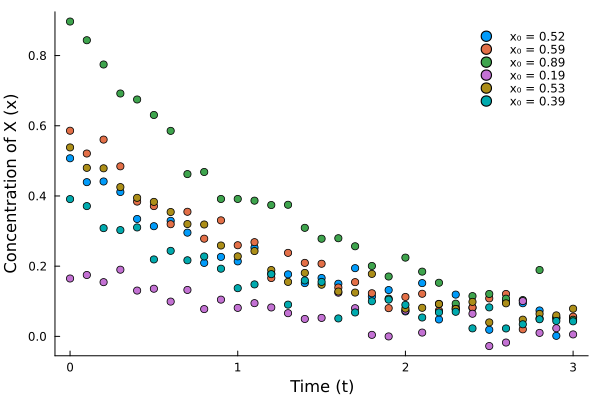

In [33]:
# 4. Plot all synthetic datasets

data_plot = plot(xlabel="Time (t)",
                 ylabel="Concentration of X (x)",
                 grid=false)

for j in 1:M
    scatter!(data_plot, times, datasets[j, :];
             label = "x₀ = $(initial_values[j])",
             fg_legend = :transparent,
             markersize = 4)
end

display(data_plot)

## The neural ODE model

We use the same small neural network as in the single-dataset example:

$$\frac{dx}{dt}=N_{\theta}(x),\qquad
N_{\theta}(x)=c+\sum_{r=1}^{4}v_r\tanh(w_rx+b_r).$$

This network has **1 input, 4 hidden neurons, and 1 output**, with $4+4+4+1=13$ trainable weights and biases. Its architecture is **unchanged** when we increase the number of datasets.

The training procedure is:

1. Define `neural_rate()` to compute $N_{\theta}(x)$.
2. Define `predict()` to solve the neural ODE for **any specified initial value**.
3. Define `loss()` to compare predictions against **all $M$ datasets**.
4. Define `train()` to optimize the **same parameter vector** using the combined loss.

We do **not** train one network per trajectory.

## Neural-network settings

- `H`: number of hidden neurons; fixed at 4 because `neural_rate()` explicitly uses four neurons.
- `iterations`: number of optimization steps. Each step now evaluates all $M$ trajectories, so training is more expensive than with one dataset.
- `learning_rate`: Adam learning rate.

Start with the values below. You may increase `iterations` if the final loss remains high.

In [5]:
# 6. Input parameters for the neural network model

H = 4                # Keep at 4: neural_rate() explicitly has four neurons
iterations = 5000    # Increase if the training loss is still high
learning_rate = 0.01


0.01

## The `neural_rate()` function

`neural_rate(x, p)` represents the right-hand side of the neural ODE, $dx/dt=N_\theta(x)$.

The parameter vector `p` contains 13 values: four input weights, four hidden biases, four output weights, and one output bias. **All datasets share these 13 parameters.**

In [6]:
# 7. The neural network is defined here through this function

# 1 input -> 4 hidden neurons -> 1 output
# Input: x
# Output: predicted dx/dt

# Function arguments
# x: Value of x
# p: Vector storing neural network parameters

function neural_rate(x, p)

    # Input weights
    w1, w2, w3, w4 = p[1:4]

    # Hidden neuron biases
    b1, b2, b3, b4 = p[5:8]

    # Output weights
    v1, v2, v3, v4 = p[9:12]

    # Output bias
    c = p[13]

    # Hidden nodes: weighted input followed by activation
    h1 = tanh(w1*x + b1)
    h2 = tanh(w2*x + b2)
    h3 = tanh(w3*x + b3)
    h4 = tanh(w4*x + b4)

    # Combine hidden neuron outputs to predict the rate
    dxdt = v1*h1 + v2*h2 + v3*h3 + v4*h4 + c

    return dxdt
end

neural_rate (generic function with 1 method)

## The `predict()` function

For any initial value $x_0$, `predict(p; initial=x0, ts=times)` numerically solves

$$\frac{dx}{dt}=N_{\theta}(x),\qquad x(t_0)=x_0.$$

We use `ODEProblem` and `solve` from `DifferentialEquations.jl`. `Tsit5()` is an **adaptive fifth-order Runge–Kutta solver** (not RK4).

For comparison, the known equation $dx/dt=-kx$ could be solved by:

```julia
problem = ODEProblem((x, k, t) -> -k*x,
                     1.0, (first(times), last(times)), k)
solution = solve(problem, Tsit5(); saveat=times)
```

For the neural ODE, replace `-k*x` with `neural_rate(x, p)`. The function accepts a different `initial` value for each dataset, but uses the **same** `p` each time.

The conversion `convert(eltype(p), initial)` lets automatic differentiation pass through the ODE solution during training.

In [7]:
# 8. Solve the neural ODE for a specified initial value
# p: shared neural-network parameters
# initial: initial value for the chosen dataset
# ts: times at which to save the solution

function predict(p; initial=initial_values[1], ts=times)

    # Keep the numerical type of p for automatic differentiation
    u0 = convert(eltype(p), initial)

    # Define dx/dt = neural_rate(x, p)
    problem = ODEProblem(
                (x, p, t) -> neural_rate(x, p),
                u0,
                (first(ts), last(ts)),
                p)

    # Solve with an adaptive fifth-order Runge-Kutta method
    solution = solve(problem, Tsit5();
                    saveat=ts,
                    abstol=1e-7,
                    reltol=1e-7)

    return solution.u
end


predict (generic function with 1 method)

## The loss function: combine all datasets

Suppose dataset $j$ contains measurements $x_i^{(j)}$ at $N$ time points, and the neural ODE predicts $\widehat{x}^{(j)}(t_i;\mathbf p)$ when started from $x_0^{(j)}$.

We minimize the **average of the mean squared errors (MSEs)** over all $M$ datasets:

$$
\boxed{L(\mathbf p)=\frac{1}{M}\sum_{j=1}^{M}
\left[\frac{1}{N}\sum_{i=1}^{N}
\left(\widehat{x}^{(j)}(t_i;\mathbf p)-x_i^{(j)}\right)^2\right]}
$$

For each dataset, we solve the neural ODE from its own initial value. Then we calculate its MSE and average these $M$ errors. The optimizer updates **one common parameter vector** `p` to reduce the combined loss.

In this example, all datasets have the same number of observations. We give each dataset equal weight.

In [8]:
# 9. Average the mean squared error across all M datasets

function loss(p)
    total_loss = zero(eltype(p))

    for j in 1:M
        # Same p, different initial value for each trajectory
        predicted = predict(p; initial=initial_values[j])

        # MSE for dataset j
        total_loss += sum(abs2, predicted .- datasets[j,:]) / length(times)
    end

    return total_loss / M
end


loss (generic function with 1 method)

## The `train()` function

`train()` is unchanged in its basic optimization strategy, but the loss now contains **all $M$ trajectories**.

Starting from random network parameters, each iteration does the following:

1. **Predict:** solve the same neural ODE separately from each of the $M$ initial values.
2. **Compare:** calculate the combined loss $L(\mathbf p)$ from all datasets.
3. **Differentiate:** use automatic differentiation to obtain
   $$g_r=\frac{\partial L}{\partial p_r}.$$
4. **Update:** Adam uses the gradient and its running statistics to update the common network parameters. In ordinary gradient descent, this would be
   $$p_r\leftarrow p_r-\alpha g_r,$$
   where $\alpha$ is the learning rate.

The loop continues for the specified number of iterations. There is no automatic stopping criterion in this code.

At the end, the function returns the trained parameters, predictions for all training datasets, and the loss before and after training.

In [9]:
# 10. Train ONE neural network using ALL datasets

function train()

    # Make the initial network parameters reproducible
    Random.seed!(42)

    # 4 input weights + 4 hidden biases + 4 output weights + 1 bias
    p = 0.2 .* randn(3H + 1)

    # Combined MSE before training
    initial_mse = loss(p)

    # Set up Adam and its running statistics
    optimizer = Optimisers.Adam(learning_rate)
    state = Optimisers.setup(optimizer, p)

    # Space for the gradient of the combined loss
    g = zeros(length(p))

    for epoch in 1:iterations
        # One gradient combines the errors of all M ODE solutions
        ForwardDiff.gradient!(g, loss, p)

        # Update the shared parameters
        state, p = Optimisers.update(state, p, g)
    end

    # Predictions for all training initial conditions
    predicted_x = [predict(p; initial=initial_values[j]) for j in 1:M]

    final_mse = loss(p)

    return p, predicted_x, initial_mse, final_mse
end


train (generic function with 1 method)

## Train the neural ODE

We now train **one shared neural network** using all datasets. Because each gradient evaluation requires $M$ ODE solutions, this will generally take longer than training on one trajectory.

We print the combined MSE before and after training. A lower training loss indicates a better fit to these observations, but we still need a separate initial condition to test generalization.

In [10]:
# 11. Train the shared neural network
n_ode = train()

println("Training complete: $M datasets, one shared neural network.\n")
println("Initial combined MSE: ", n_ode[3])
println("Final combined MSE:   ", n_ode[4])


Training complete: 6 datasets, one shared neural network.

Initial combined MSE: 0.02581549418957634
Final combined MSE:   0.0008450060730944717


## Compare the trained model with every dataset

For each initial value, plot the observed data as points and the neural ODE prediction as a line. Each pair corresponds to a separate ODE solve, but **all predicted curves use exactly the same trained neural-network parameters**.

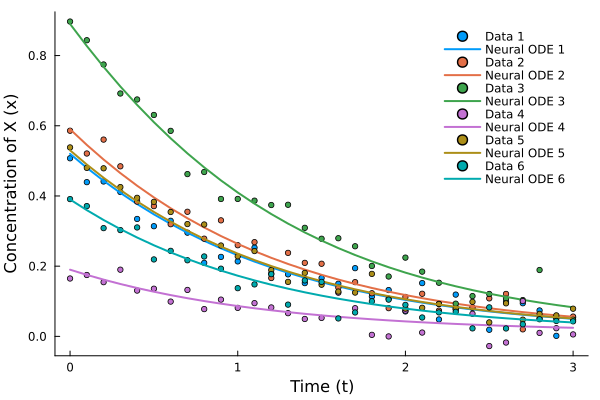

In [36]:
# 12. Overlay each dataset with its prediction

plot_compare = plot(xlabel = "Time (t)",
                 ylabel = "Concentration of X (x)",
                 fg_legend = :transparent,
                 grid = false)

for j in 1:M
    scatter!(plot_compare, times, datasets[j, :];
             label = "Data $j", color = j, markersize = 3)
    plot!(plot_compare, times, n_ode[2][j];
          label = "Neural ODE $j", color = j, linewidth = 2)
end

display(plot_compare)


## Test a new initial condition

We now test the trained neural ODE with an initial value **not included among the training initial values**.

The network parameters stay fixed; we change only the initial condition passed to `predict()`.

We compare the learned trajectory against the exact solution $x(t)=x_0e^{-kt}$, which is known because this is a synthetic-data exercise. This test is more informative than comparing training trajectories alone.

Try a new initial condition within the training range first (interpolation), and then outside the range (extrapolation). Good extrapolation is **not guaranteed**.

In [51]:
# 13. Test an initial value not used in training

new_x0 = 1.2


1.2

In [52]:
# 14. Predict using the SAME trained parameters

trained_p = n_ode[1]
new_predicted = predict(trained_p; initial=new_x0);


In [53]:
# 15. Exact solution for comparison (not used in training)

new_data = new_x0 .* exp.(-k .* times);


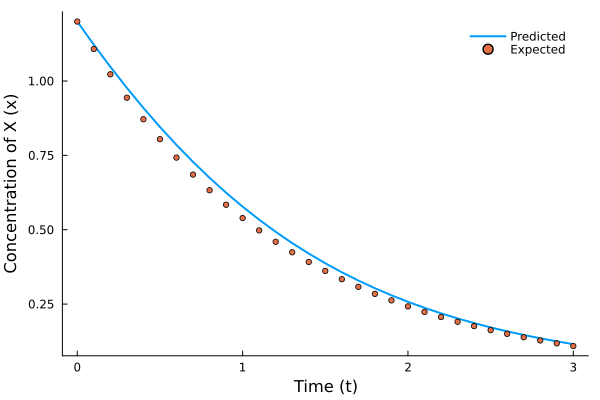

In [54]:
# 16. Compare the new prediction with the exact solution

plot(times, new_predicted;
     xlabel="Time (t)",
     ylabel="Concentration of X (x)",
     label="Predicted",
     fg_legend = :transparent,
     linewidth=2,
     grid=false)

scatter!(times, new_data; 
    label="Expected", 
    markersize=3)
